# Tugas 3 Pengolahan Citra Digital
## PCD_Assignment03

Segmentasi K-means dan pengaruh erosi, dilasi, opening, serta closing.
Eksperimen membandingkan mask segmentasi yang sama sebelum dan sesudah morfologi.
Seluruh algoritma ditulis dari awal. NumPy digunakan untuk array dan operasi dasar,
Pillow untuk membaca serta menyimpan gambar, Matplotlib untuk visualisasi,
dan pandas untuk menyusun tabel.

Jalankan semua sel secara berurutan. Gambar dapat dibaca dari folder lokal atau
diunduh dari repo saat notebook dibuka di Colab. Hasil disimpan ke data/output.


In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "figure.dpi": 110,
})
pd.set_option("display.max_rows", 30)
INPUT = Path("data/input")
OUTPUT = Path("data/output")
INPUT.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"NumPy {np.__version__}; pandas {pd.__version__}")


NumPy 2.5.4; pandas 3.1.0


## 1 Segmentasi K-means

Fitur setiap piksel adalah intensitas grayscale. Dengan k=2, satu kelompok berisi
intensitas rendah dan satu kelompok intensitas tinggi. Centroid awal diambil dari
intensitas minimum dan maksimum agar percobaan deterministik.

Langkahnya: hitung jarak kuadrat piksel ke kedua centroid, pilih centroid terdekat,
lalu hitung ulang rata-rata tiap kelompok. Iterasi berhenti saat perpindahan centroid
<= 0.001 atau sudah mencapai 100 iterasi. Cluster kosong mempertahankan centroid
sebelumnya. Citra konstan ditolak karena tidak mempunyai dua tingkat intensitas.

Fungsi meminimalkan SSE = total (intensitas piksel - centroid cluster)^2.
Label diurutkan berdasarkan centroid. Foreground dipilih dari cluster terang untuk
koin dan bentuk sintetis, serta cluster gelap untuk teks. Pilihan tersebut berasal
dari karakter objek pada input, bukan dari skor mask acuan.


In [2]:
def kmeans_gray(image, max_iter=100, tol=0.001):
    """Dua cluster intensitas; label 0 selalu memiliki centroid lebih rendah."""
    image = np.asarray(image)
    if image.ndim != 2 or image.size == 0:
        raise ValueError("Input harus berupa citra grayscale yang tidak kosong.")
    if max_iter < 1 or tol < 0 or not np.isfinite(image).all():
        raise ValueError("Periksa nilai piksel, max_iter, dan tol.")
    pixels = image.astype(np.float64).ravel()
    centers = np.array([pixels.min(), pixels.max()])
    if centers[0] == centers[1]:
        raise ValueError("Citra konstan tidak dapat dipisahkan menjadi dua intensitas.")
    history = [centers.copy()]
    losses = []

    for _ in range(max_iter):
        distances = (pixels[:, None] - centers[None, :]) ** 2
        labels = np.argmin(distances, axis=1)
        updated = centers.copy()
        for cluster in range(2):
            members = pixels[labels == cluster]
            if members.size:
                updated[cluster] = members.mean()
        losses.append(float(((pixels - updated[labels]) ** 2).sum()))
        history.append(updated.copy())
        shift = np.max(np.abs(updated - centers))
        centers = updated
        if shift <= tol:
            break

    centers.sort()
    labels = np.argmin((pixels[:, None] - centers[None, :]) ** 2, axis=1)
    return labels.reshape(image.shape), centers, np.array(history), np.array(losses)


## 2 Operasi morfologi

Mask memakai True untuk foreground dan False untuk background. Percobaan utama
menggunakan structuring element persegi 3 x 3, dengan pusat di tengah.

| Operasi | Aturan |
| :--- | :--- |
| Erosi | Piksel tetap foreground jika seluruh posisi aktif element berada di foreground. |
| Dilasi | Piksel menjadi foreground jika salah satu posisi aktif element mengenai foreground. |
| Opening | Erosi dilanjutkan dilasi dengan element yang sama. |
| Closing | Dilasi dilanjutkan erosi dengan element yang sama. |

Loop memeriksa setiap posisi aktif element, sedangkan NumPy mengerjakan operasi
logika pada array. Tidak ada pemanggilan fungsi morfologi siap pakai.
Piksel di luar citra dianggap background. Closing menambahkan margin sementara
agar hasil dilasi di luar bingkai tidak hilang sebelum langkah erosi.


In [3]:
def check_binary(mask, element):
    mask = np.asarray(mask)
    element = np.asarray(element)
    if mask.ndim != 2 or mask.size == 0:
        raise ValueError("Mask harus berupa array dua dimensi yang tidak kosong.")
    if element.ndim != 2 or 0 in element.shape:
        raise ValueError("Structuring element harus berupa array dua dimensi.")
    if any(size % 2 == 0 for size in element.shape):
        raise ValueError("Ukuran structuring element harus ganjil.")
    if not np.isin(mask, [0, 1]).all() or not np.isin(element, [0, 1]).all():
        raise ValueError("Mask dan structuring element hanya boleh berisi 0 dan 1.")
    if not element[element.shape[0] // 2, element.shape[1] // 2]:
        raise ValueError("Pusat structuring element harus aktif.")
    return mask.astype(bool), element.astype(bool)


def erode(mask, element):
    mask, element = check_binary(mask, element)
    height, width = mask.shape
    ry, rx = element.shape[0] // 2, element.shape[1] // 2
    padded = np.pad(mask, ((ry, ry), (rx, rx)), constant_values=False)
    result = np.ones_like(mask)
    for row, col in np.argwhere(element):
        result &= padded[row:row + height, col:col + width]
    return result


def dilate(mask, element):
    mask, element = check_binary(mask, element)
    height, width = mask.shape
    ry, rx = element.shape[0] // 2, element.shape[1] // 2
    padded = np.pad(mask, ((ry, ry), (rx, rx)), constant_values=False)
    result = np.zeros_like(mask)
    for row, col in np.argwhere(element):
        # Refleksi diperlukan untuk element yang tidak simetris.
        y, x = 2 * ry - row, 2 * rx - col
        result |= padded[y:y + height, x:x + width]
    return result


def opening(mask, element):
    return dilate(erode(mask, element), element)


def closing(mask, element):
    mask, element = check_binary(mask, element)
    height, width = mask.shape
    ry, rx = element.shape[0] // 2, element.shape[1] // 2
    # Pertahankan hasil dilasi di luar bingkai sampai erosi selesai.
    padded = np.pad(mask, ((ry, ry), (rx, rx)), constant_values=False)
    result = erode(dilate(padded, element), element)
    return result[ry:ry + height, rx:rx + width]


def morphology_variants(mask, element):
    return {
        "Tanpa morfologi": mask.copy(),
        "Erosi": erode(mask, element),
        "Dilasi": dilate(mask, element),
        "Opening": opening(mask, element),
        "Closing": closing(mask, element),
        "Opening + closing": closing(opening(mask, element), element),
    }


### Pemeriksaan pada mask kecil

Satu piksel menghasilkan blok 3 x 3 setelah dilasi. Erosi mengembalikan blok
tersebut menjadi satu piksel. Opening menghapus satu bintik terpisah dan closing
menutup satu lubang. Contoh yang menyentuh tepi juga diperiksa.


In [4]:
element = np.ones((3, 3), dtype=bool)
single = np.zeros((9, 9), dtype=bool)
single[4, 4] = True
block = np.zeros_like(single)
block[3:6, 3:6] = True
assert np.array_equal(dilate(single, element), block)
assert np.array_equal(erode(block, element), single)
assert not opening(single, element).any()
with_hole = np.zeros_like(single)
with_hole[1:8, 1:8] = True
with_hole[4, 4] = False
assert closing(with_hole, element)[4, 4]
edge_block = np.zeros_like(single)
edge_block[:4, :4] = True
assert np.array_equal(closing(edge_block, element), edge_block)
print("Pemeriksaan mask kecil berhasil.")


Pemeriksaan mask kecil berhasil.


## 3 Evaluasi

IoU = TP / (TP + FP + FN) dan Dice = 2 * TP / (2 * TP + FP + FN).
Precision dan recall membantu membedakan piksel berlebih dari objek yang hilang.
Metrik ini hanya dihitung pada citra sintetis yang memiliki mask acuan geometris.

Untuk semua citra, flood fill menghitung komponen foreground dengan konektivitas 8.
Lubang adalah komponen background berkonektivitas 4 yang tidak menyentuh tepi.
Pasangan konektivitas yang berbeda menghindari ambiguitas pada pertemuan diagonal.
Komponen dengan luas <= 9 piksel dicatat sebagai komponen kecil; sebagian dapat
merupakan detail objek yang sah. Berkurangnya komponen bukan ukuran akurasi.

Jika prediksi dan acuan sama-sama kosong, IoU dan Dice didefinisikan 1.
Precision bernilai 0 bila prediksi kosong tetapi acuan tidak kosong.


In [5]:
def connected_components(mask, connectivity=8):
    """Flood fill; kembalikan luas dan status menyentuh tepi tiap komponen."""
    mask = np.asarray(mask, dtype=bool)
    if mask.ndim != 2 or connectivity not in (4, 8):
        raise ValueError("Gunakan mask dua dimensi dan konektivitas 4 atau 8.")
    height, width = mask.shape
    visited = np.zeros_like(mask)
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if connectivity == 8:
        neighbors += [(-1, -1), (-1, 1), (1, -1), (1, 1)]
    areas, touches_border = [], []
    for row in range(height):
        for col in range(width):
            if not mask[row, col] or visited[row, col]:
                continue
            visited[row, col] = True
            stack = [(row, col)]
            area, border = 0, False
            while stack:
                y, x = stack.pop()
                area += 1
                border |= y == 0 or y == height - 1 or x == 0 or x == width - 1
                for dy, dx in neighbors:
                    ny, nx = y + dy, x + dx
                    if (0 <= ny < height and 0 <= nx < width
                            and mask[ny, nx] and not visited[ny, nx]):
                        visited[ny, nx] = True
                        stack.append((ny, nx))
            areas.append(area)
            touches_border.append(border)
    return np.array(areas, dtype=int), np.array(touches_border, dtype=bool)


def structural_metrics(mask):
    areas, _ = connected_components(mask, 8)
    _, background_border = connected_components(~mask, 4)
    return {
        "Area (%)": 100 * float(mask.mean()),
        "Komponen": len(areas),
        "Komponen <=9 px": int((areas <= 9).sum()),
        "Lubang": int((~background_border).sum()),
    }


def segmentation_metrics(prediction, reference):
    prediction = np.asarray(prediction, dtype=bool)
    reference = np.asarray(reference, dtype=bool)
    if prediction.shape != reference.shape:
        raise ValueError("Ukuran prediksi dan mask acuan harus sama.")
    tp = int((prediction & reference).sum())
    fp = int((prediction & ~reference).sum())
    fn = int((~prediction & reference).sum())
    return {
        "IoU": tp / (tp + fp + fn) if tp + fp + fn else 1.0,
        "Dice": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0,
        "Precision": tp / (tp + fp) if tp + fp else float(tp + fn == 0),
        "Recall": tp / (tp + fn) if tp + fn else 1.0,
        "FP": fp,
        "FN": fn,
    }


## 4 Citra uji

1. Koin, 384 x 303 piksel. Relief dan pencahayaan membuat beberapa bagian koin
   mempunyai intensitas serupa latar. Kasus ini menguji keterbatasan segmentasi
   berbasis intensitas dan perubahan batas setelah morfologi.
2. Halaman teks, 384 x 191 piksel. Goresan huruf dan celah antarhuruf berukuran kecil.
   Kasus ini menguji risiko hilangnya goresan atau bergabungnya huruf.
3. Bentuk sintetis, 320 x 256 piksel. Mask dibangun dari lingkaran, elips, persegi
   panjang, objek kecil, dan penghubung tipis. Mask tersebut menjadi acuan sebelum
   intensitas diberi derau Gaussian (sigma 7) dan impuls sebanyak 2.5% secara probabilistik.

Gambar koin dan halaman teks berasal dari koleksi contoh scikit-image, digunakan
pada ukuran asli tanpa resize dan tanpa penambahan derau. Paket scikit-image tidak
dibutuhkan untuk menjalankan notebook. Citra sintetis dibuat di bawah dengan seed 31.
Mask acuannya tidak dihasilkan dari K-means atau morfologi.


In [6]:
def make_synthetic(seed=31):
    """Mask dibuat dari geometri sebelum penambahan derau pada intensitas."""
    y, x = np.indices((256, 320))
    reference = (x - 65) ** 2 + (y - 65) ** 2 <= 36 ** 2
    reference |= ((x - 219) / 49) ** 2 + ((y - 66) / 28) ** 2 <= 1
    reference |= (x >= 38) & (x < 119) & (y >= 159) & (y < 215)
    reference |= (x >= 193) & (x < 241) & (y >= 164) & (y < 215)
    reference |= (x >= 241) & (x < 279) & (y >= 189) & (y < 192)
    reference |= (x >= 279) & (x < 298) & (y >= 181) & (y < 201)
    reference |= (x - 143) ** 2 + (y - 117) ** 2 <= 3 ** 2
    rng = np.random.default_rng(seed)
    image = np.where(reference, 183 + 10 * np.sin(x / 13), 38 + 15 * x / 320)
    image += rng.normal(0, 7, image.shape)
    noise = rng.random(image.shape)
    image[noise < 0.0125] = 245
    image[(noise >= 0.0125) & (noise < 0.025)] = 8
    return np.clip(np.rint(image), 0, 255).astype(np.uint8), reference


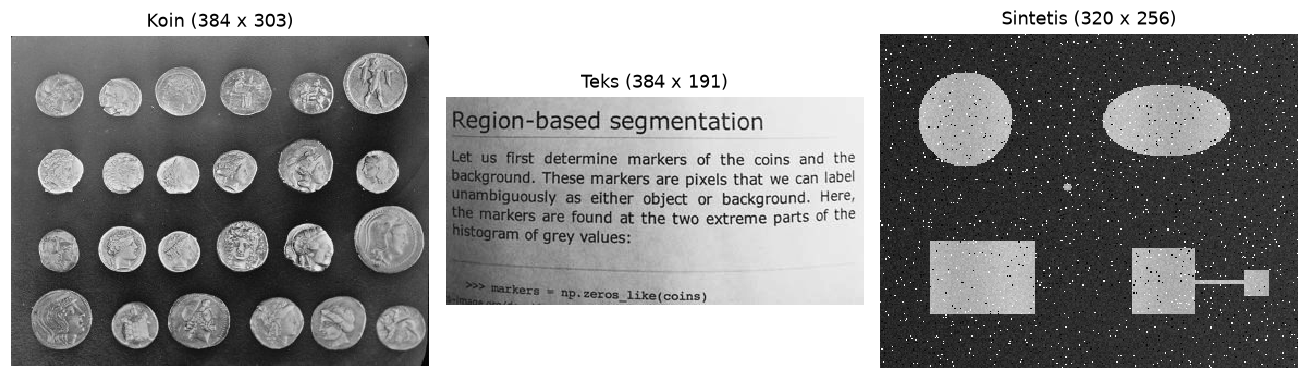

In [7]:
RAW_BASE = "https://raw.githubusercontent.com/hanafishiddiq/PCD_Assignment03/main/data/input"

def load_gray(filename):
    path = INPUT / filename
    if path.exists():
        with Image.open(path) as image:
            return np.array(image.convert("L"))
    with urlopen(f"{RAW_BASE}/{filename}", timeout=30) as response:
        raw = response.read()
    with Image.open(BytesIO(raw)) as image:
        gray = np.array(image.convert("L"))
    Image.fromarray(gray).save(path)
    return gray

synthetic, reference = make_synthetic()
Image.fromarray(synthetic).save(INPUT / "synthetic.png")
Image.fromarray(reference.astype(np.uint8) * 255).save(INPUT / "synthetic_mask.png")
dataset = {
    "Koin": {"image": load_gray("coins.png"), "foreground": 1},
    "Teks": {"image": load_gray("page.png"), "foreground": 0},
    "Sintetis": {"image": synthetic, "foreground": 1, "reference": reference},
}

def show_gray(ax, image, title):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1 if image.dtype == bool else 255,
              interpolation="nearest")
    ax.set_title(title, color="black")
    ax.axis("off")

def save_figure(fig, name):
    fig.savefig(OUTPUT / name, dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, item) in zip(axes, dataset.items()):
    height, width = item["image"].shape
    show_gray(ax, item["image"], f"{name} ({width} x {height})")
fig.tight_layout()
save_figure(fig, "dataset_overview.png")


## 5 Perbandingan tanpa dan dengan morfologi

K-means dijalankan sekali per input. Keenam perlakuan menerima mask awal yang sama.
Selain empat operasi tersendiri, opening dilanjutkan closing diuji untuk menghapus
bintik foreground lalu menutup lubang kecil. Kernel utama 3 x 3 ditetapkan sebelum
melihat skor, bukan dipilih untuk memaksimalkan IoU.

Mask acuan ditampilkan bersama keenam perlakuan. Panel galat kombinasi memakai putih untuk FP, hitam untuk FN, dan abu-abu untuk piksel yang benar.


,Citra,Centroid gelap,Centroid terang,Iterasi,Konvergen
0,Koin,60.255,154.644,7,True
1,Teks,107.549,207.804,8,True
2,Sintetis,45.069,185.644,2,True


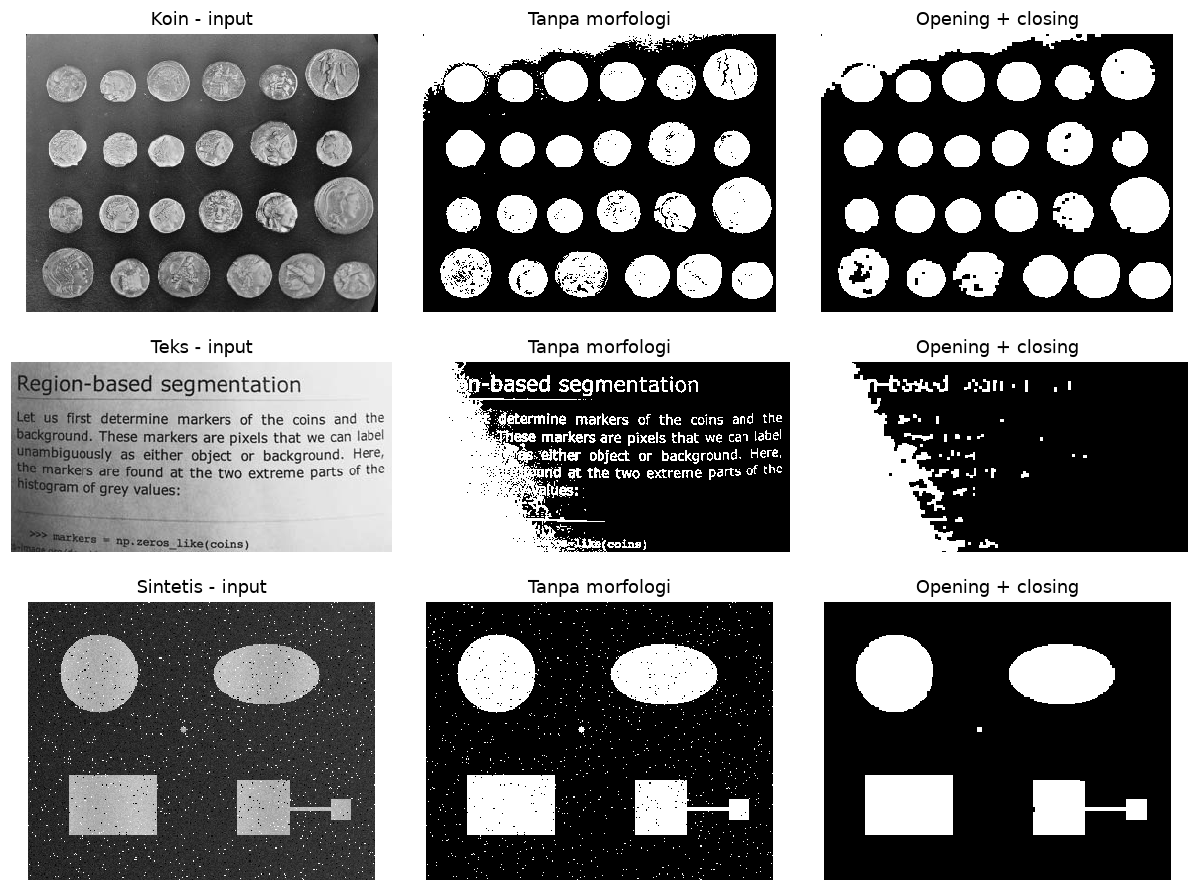

In [8]:
results = {}
records, centroid_records = [], []
for name, item in dataset.items():
    labels, centers, history, losses = kmeans_gray(item["image"])
    mask = labels == item["foreground"]
    variants = morphology_variants(mask, element)
    results[name] = {"variants": variants, "centers": centers,
                     "history": history, "losses": losses}
    centroid_records.append({
        "Citra": name, "Centroid gelap": centers[0], "Centroid terang": centers[1],
        "Iterasi": len(losses), "Konvergen": bool(np.max(np.abs(history[-1] - history[-2])) <= 0.001),
    })
    for index, (method, processed) in enumerate(variants.items()):
        record = {"Citra": name, "Perlakuan": method, **structural_metrics(processed)}
        if "reference" in item:
            record.update(segmentation_metrics(processed, item["reference"]))
        records.append(record)
        Image.fromarray(processed.astype(np.uint8) * 255).save(
            OUTPUT / f"{name.lower()}_{index:02d}.png"
        )

metrics = pd.DataFrame(records)
centroids = pd.DataFrame(centroid_records)
metrics.to_csv(OUTPUT / "segmentation_metrics.csv", index=False, float_format="%.8f")
centroids.to_csv(OUTPUT / "kmeans_centroids.csv", index=False, float_format="%.8f")
display(centroids.round(3))

fig, axes = plt.subplots(3, 3, figsize=(11, 8.2))
for row, (name, item) in enumerate(dataset.items()):
    show_gray(axes[row, 0], item["image"], f"{name} - input")
    show_gray(axes[row, 1], results[name]["variants"]["Tanpa morfologi"], "Tanpa morfologi")
    show_gray(axes[row, 2], results[name]["variants"]["Opening + closing"], "Opening + closing")
fig.tight_layout()
save_figure(fig, "segmentation_comparison.png")


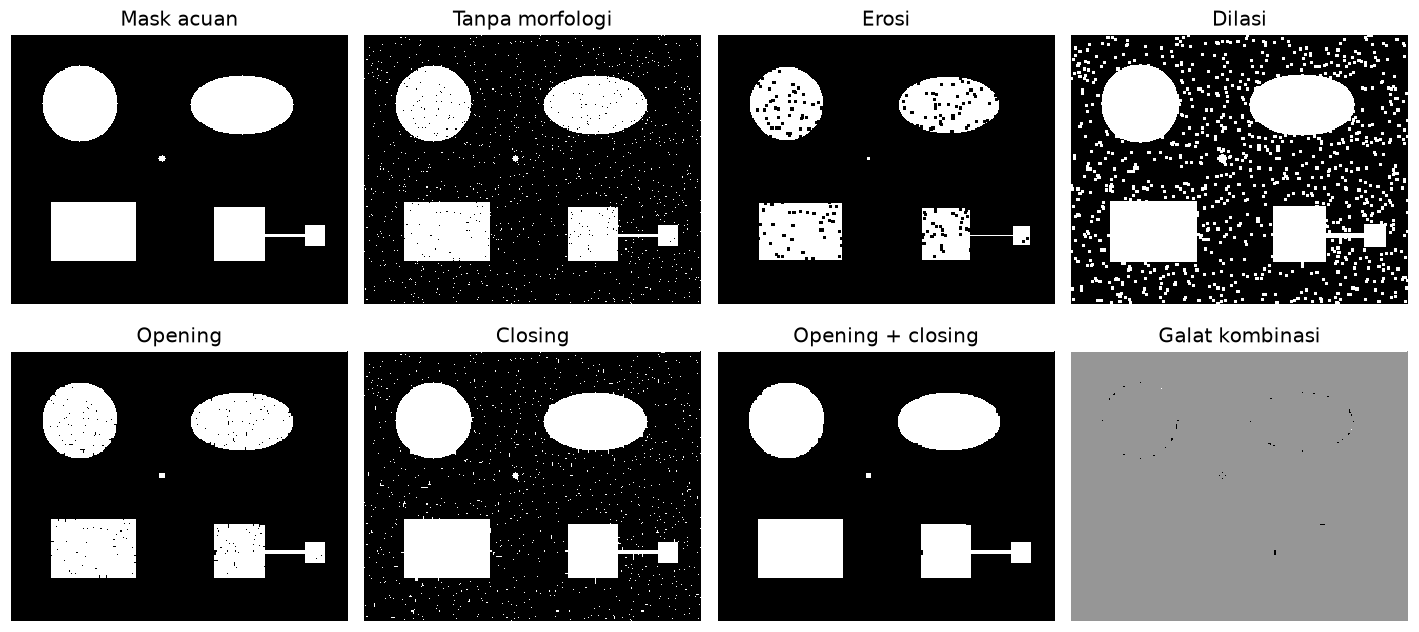

,Perlakuan,IoU,Dice,Precision,Recall,FP,FN
12,Tanpa morfologi,0.9353,0.9666,0.9461,0.9880,893.0,191.0
13,Erosi,0.8289,0.9065,1.0000,0.8289,0.0,2713.0
14,Dilasi,0.6454,0.7845,0.6454,1.0000,8715.0,0.0
15,Opening,0.9817,0.9908,0.9999,0.9818,2.0,288.0
16,Closing,0.9382,0.9681,0.9383,0.9999,1043.0,1.0
17,Opening + closing,0.9955,0.9977,0.9999,0.9956,2.0,70.0


In [9]:
panels = [("Mask acuan", reference)] + list(results["Sintetis"]["variants"].items())
combined = results["Sintetis"]["variants"]["Opening + closing"]
errors = np.full(reference.shape, 150, dtype=np.uint8)
errors[combined & ~reference] = 255
errors[~combined & reference] = 0
panels.append(("Galat kombinasi", errors))

fig, axes = plt.subplots(2, 4, figsize=(13, 6.1))
for ax, (label, mask) in zip(axes.flat, panels):
    show_gray(ax, mask, label)
    ax.set_title(label, fontsize=13, color="black")
fig.tight_layout()
save_figure(fig, "morphology_operations.png")

synthetic_metrics = metrics[metrics["Citra"] == "Sintetis"].copy()
display(synthetic_metrics[["Perlakuan", "IoU", "Dice", "Precision", "Recall", "FP", "FN"]].round(4))


### Lokasi galat pada citra sintetis

Mask acuan dibandingkan langsung dengan prediksi. Pada peta galat: putih adalah
false positive, hitam adalah false negative, dan abu-abu adalah piksel yang benar.
Perhatikan objek kecil serta penghubung tipis yang dapat ikut terhapus.


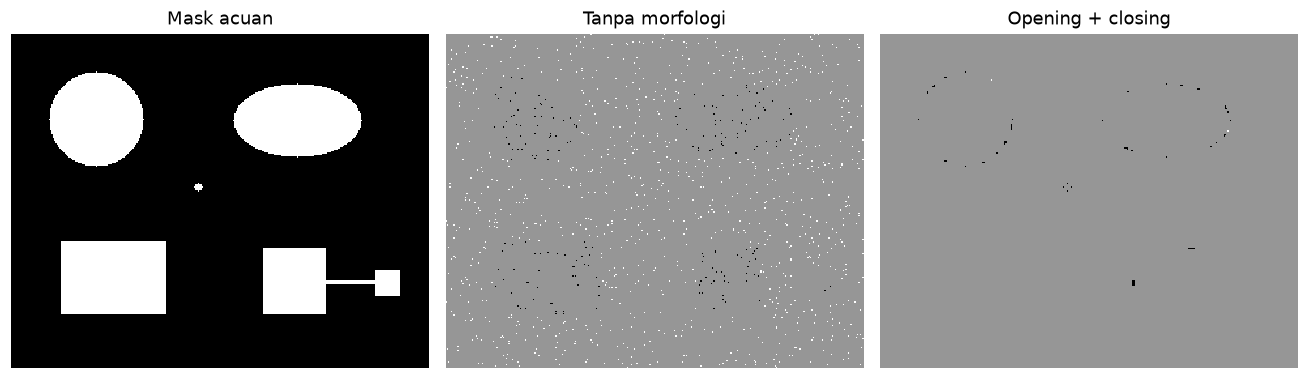

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
show_gray(axes[0], reference, "Mask acuan")
for ax, method in zip(axes[1:], ["Tanpa morfologi", "Opening + closing"]):
    mask = results["Sintetis"]["variants"][method]
    errors = np.full(reference.shape, 150, dtype=np.uint8)
    errors[mask & ~reference] = 255
    errors[~mask & reference] = 0
    show_gray(ax, errors, method)
fig.tight_layout()
save_figure(fig, "synthetic_errors.png")


### Perubahan struktur pada citra nyata

Komponen yang terhitung tidak otomatis sama dengan jumlah koin atau jumlah huruf.
Tanpa anotasi acuan, tabel berikut hanya mendeskripsikan perubahan mask.
Perbandingan seluruh operasi disimpan sebagai gambar agar efek erosi dan dilasi
tidak tertutupi oleh hasil kombinasi.


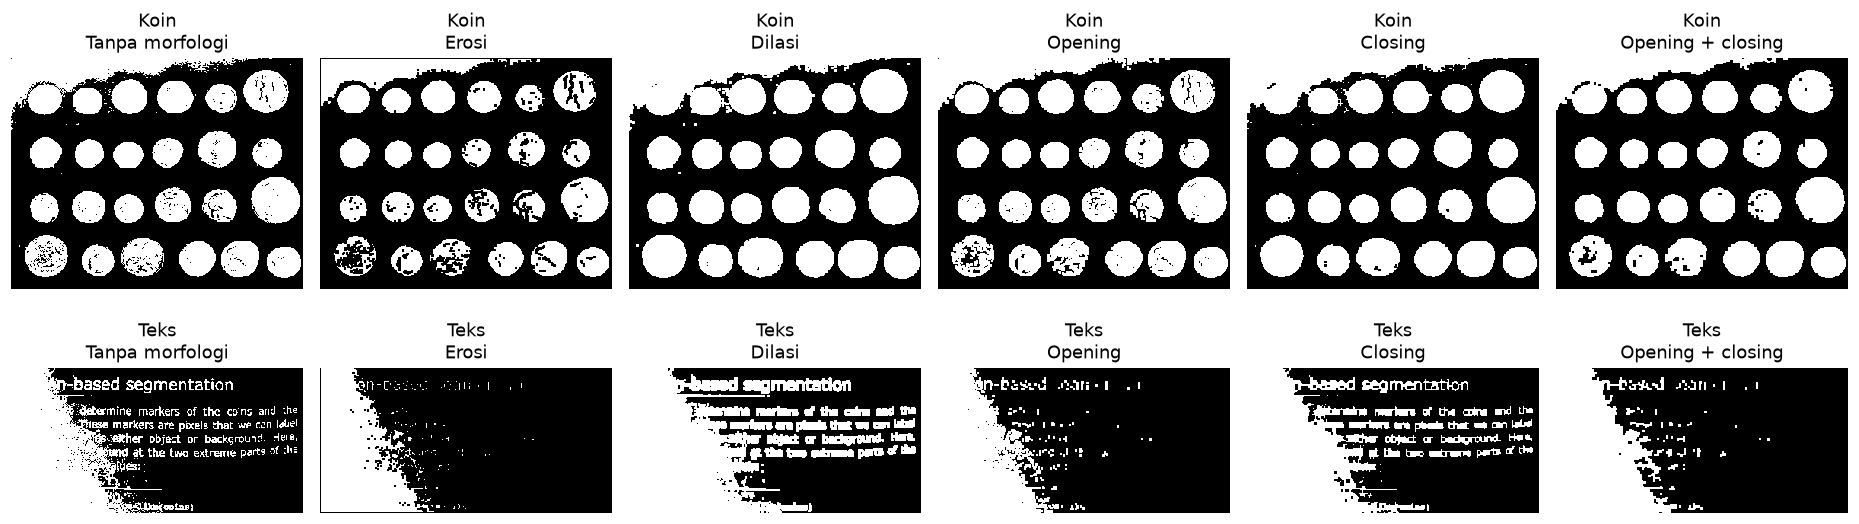

,Citra,Perlakuan,Area (%),Komponen,Komponen <=9 px,Lubang
0,Koin,Tanpa morfologi,38.78,96,70,533
1,Koin,Erosi,30.26,62,27,87
2,Koin,Dilasi,45.13,37,5,17
3,Koin,Opening,37.44,35,0,212
4,Koin,Closing,40.51,57,32,9
5,Koin,Opening + closing,38.46,25,0,24
6,Teks,Tanpa morfologi,36.17,230,102,374
7,Teks,Erosi,22.93,142,127,31
8,Teks,Dilasi,48.89,34,5,82
9,Teks,Opening,27.75,88,23,76


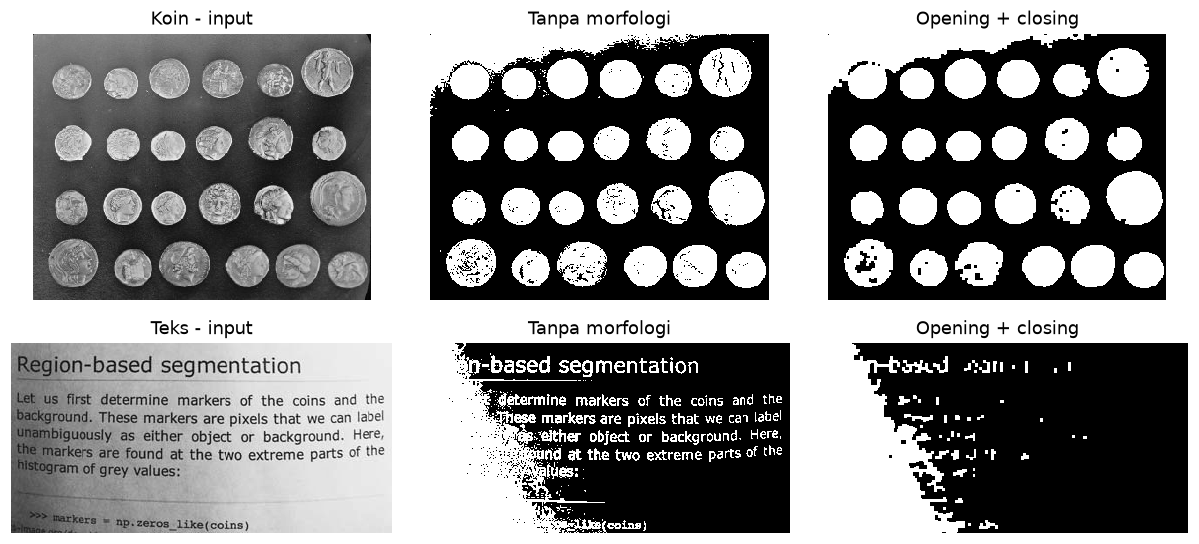

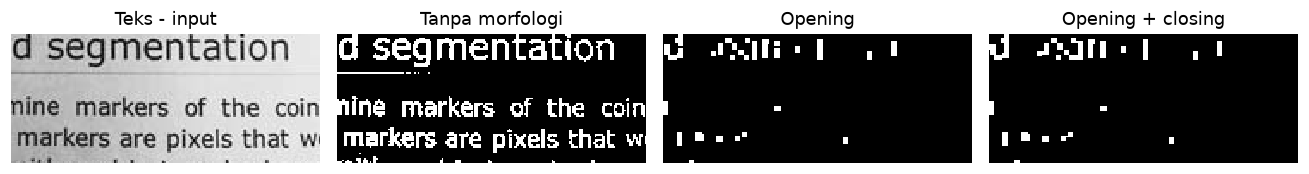

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(17, 5.5))
for row, name in enumerate(["Koin", "Teks"]):
    for ax, (method, mask) in zip(axes[row], results[name]["variants"].items()):
        show_gray(ax, mask, f"{name}\n{method}")
fig.tight_layout()
save_figure(fig, "real_morphology_operations.png")
display(metrics[metrics["Citra"] != "Sintetis"][
    ["Citra", "Perlakuan", "Area (%)", "Komponen", "Komponen <=9 px", "Lubang"]
].round(2))

fig, axes = plt.subplots(2, 3, figsize=(11, 5.4))
for row, name in enumerate(["Koin", "Teks"]):
    show_gray(axes[row, 0], dataset[name]["image"], f"{name} - input")
    for ax, method in zip(axes[row, 1:], ["Tanpa morfologi", "Opening + closing"]):
        show_gray(ax, results[name]["variants"][method], method)
fig.tight_layout()
save_figure(fig, "real_comparison.png")

# Area teks yang sama dipakai untuk semua perlakuan.
roi = np.s_[15:90, 130:310]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.1))
show_gray(axes[0], dataset["Teks"]["image"][roi], "Teks - input")
for ax, method in zip(axes[1:], ["Tanpa morfologi", "Opening", "Opening + closing"]):
    show_gray(ax, results["Teks"]["variants"][method][roi], method)
fig.tight_layout()
save_figure(fig, "text_detail.png")


## 6 Pengaruh structuring element

Persegi 3 x 3, 5 x 5, 7 x 7, dan silang 3 x 3 digunakan untuk urutan opening lalu
closing yang sama. Kernel lebih besar memengaruhi detail pada skala yang lebih
besar. Percobaan ini menunjukkan sensitivitas parameter, bukan pencarian parameter
terbaik yang kemudian dianggap berlaku untuk semua citra.

Label "Tidak dinilai" pada IoU dan Dice berarti citra tidak mempunyai mask acuan, sehingga akurasinya tidak dihitung.


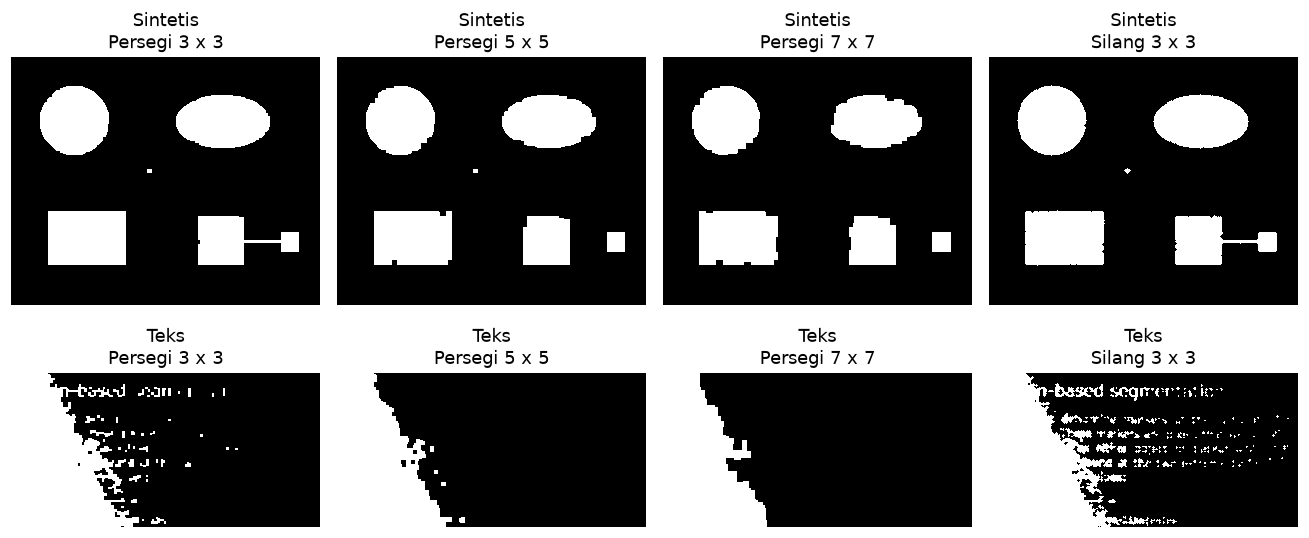

,Citra,Element,Area (%),Komponen,IoU,Dice
0,Sintetis,Persegi 3 x 3,19.2761,5,0.9955,0.9977
1,Teks,Persegi 3 x 3,28.6322,45,Tidak dinilai,Tidak dinilai
2,Sintetis,Persegi 5 x 5,18.8135,6,0.9716,0.9856
3,Teks,Persegi 5 x 5,24.017,5,Tidak dinilai,Tidak dinilai
4,Sintetis,Persegi 7 x 7,18.2678,5,0.9434,0.9709
5,Teks,Persegi 7 x 7,22.824,1,Tidak dinilai,Tidak dinilai
6,Sintetis,Silang 3 x 3,19.2822,5,0.9943,0.9971
7,Teks,Silang 3 x 3,32.2221,159,Tidak dinilai,Tidak dinilai


In [12]:
elements = {
    "Persegi 3 x 3": np.ones((3, 3), dtype=bool),
    "Persegi 5 x 5": np.ones((5, 5), dtype=bool),
    "Persegi 7 x 7": np.ones((7, 7), dtype=bool),
    "Silang 3 x 3": np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool),
}
sensitivity_records = []
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
for col, (label, current_element) in enumerate(elements.items()):
    for row, name in enumerate(["Sintetis", "Teks"]):
        initial = results[name]["variants"]["Tanpa morfologi"]
        mask = closing(opening(initial, current_element), current_element)
        record = {"Citra": name, "Element": label, **structural_metrics(mask)}
        if name == "Sintetis":
            record.update(segmentation_metrics(mask, reference))
        sensitivity_records.append(record)
        show_gray(axes[row, col], mask, f"{name}\n{label}")
fig.tight_layout()
save_figure(fig, "kernel_comparison.png")
sensitivity = pd.DataFrame(sensitivity_records)
sensitivity.to_csv(OUTPUT / "kernel_sensitivity.csv", index=False, float_format="%.8f")
sensitivity_display = sensitivity[["Citra", "Element", "Area (%)", "Komponen", "IoU", "Dice"]].round(4).astype(object)
display(sensitivity_display.where(pd.notna(sensitivity_display), "Tidak dinilai"))


## 7 Analisis hasil

Pada citra sintetis, opening lalu closing menaikkan IoU dari 0.9353
menjadi 0.9955 dan Dice dari 0.9666 menjadi 0.9977.
FP turun dari 893 menjadi 2, sedangkan FN turun dari
191 menjadi 70. Erosi sendiri mengecilkan objek dan
dilasi sendiri membesarkan bintik derau. Opening menghapus bintik, lalu closing
menutup lubang kecil yang tersisa.

Pada koin, opening lalu closing menurunkan lubang dari 533 menjadi 24 dan komponen
kecil dari 70 menjadi 0. Namun latar terang di kiri atas tetap salah menjadi
foreground dan beberapa lubang besar masih ada. Jumlah komponen akhir 25 tidak
dapat diperlakukan sebagai bukti bahwa semua koin terpisah dengan benar.

Pada teks, goresan huruf banyak yang hilang setelah opening. Area foreground turun
dari 36.17% menjadi 28.63%, tetapi penurunan luas ini bukan perbaikan keterbacaan.
Bayangan di sisi kiri sudah menjadi foreground sejak K-means dan tidak dapat
diperbaiki hanya dengan perubahan bentuk mask. Closing juga tidak memulihkan
huruf yang telah hilang saat opening.

Persegi 5 x 5 memutus penghubung tiga piksel pada sintetis; persegi 7 x 7 ikut
menghapus objek kecil. FN meningkat dari 70 menjadi 449 dan 896. Silang 3 x 3
mempertahankan lebih banyak goresan teks dibanding persegi, tetapi tidak
menyelesaikan bayangan latar.

Morfologi perlu dipilih sesuai skala derau dan detail objek. Kombinasi yang membantu
pada bentuk geometris belum tentu cocok untuk teks. IoU dan Dice hanya dihitung
pada sintetis; citra nyata tidak memiliki mask acuan pada eksperimen ini.

## 8 Referensi

- Segmentation.
- Morphological Processing.
- [scikit-image example images and datasets](https://scikit-image.org/docs/stable/api/skimage.data.html).
  Gambar coins dan page dipakai sebagai data, tanpa memakai fungsi algoritma paket tersebut.
